In [3]:
import io
import os
import pandas as pd
import paramiko
import matplotlib.pyplot as plt
df=pd.read_pickle('combined_data.pkl')

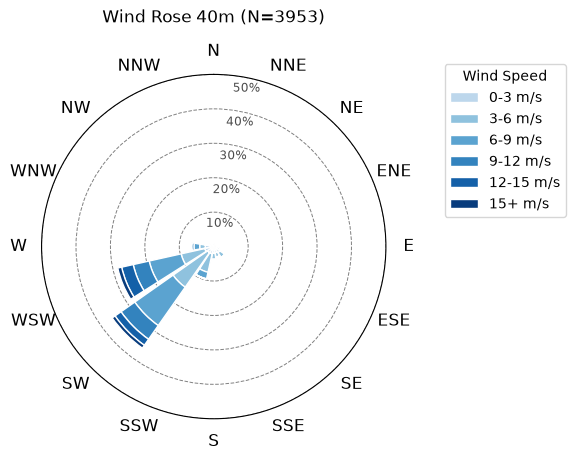

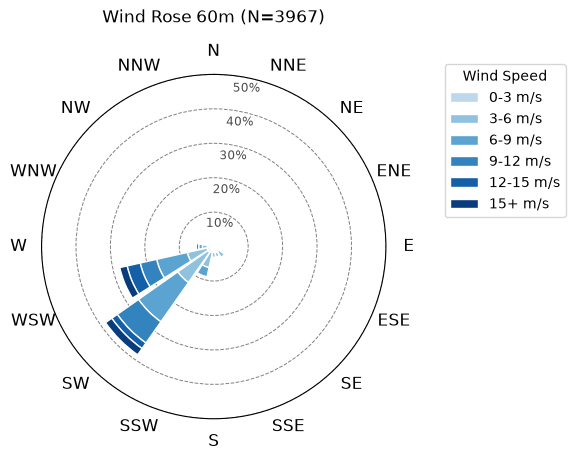

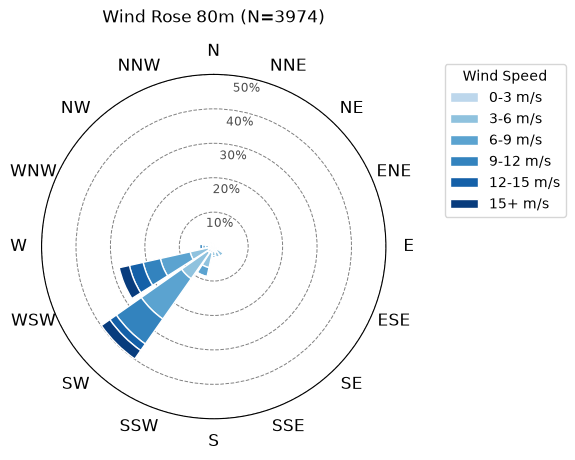

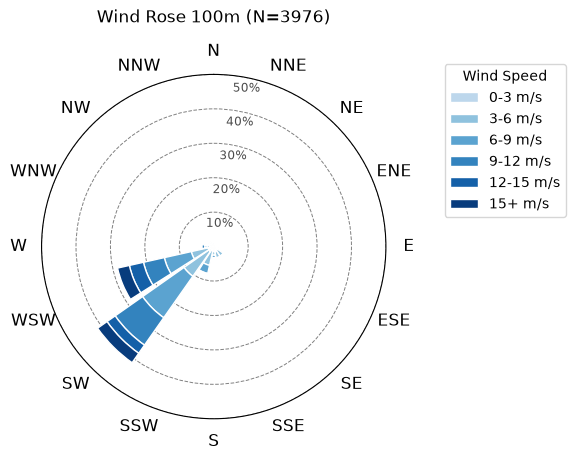

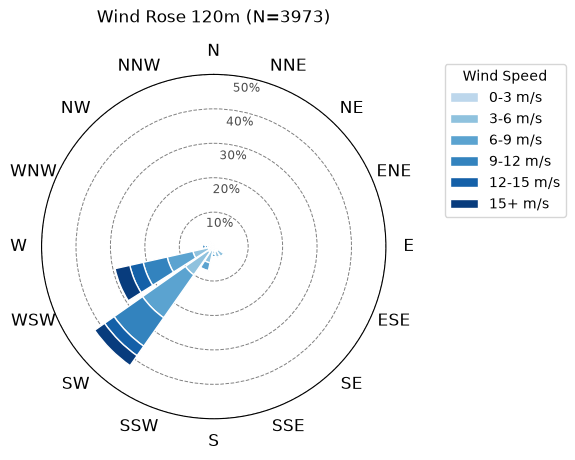

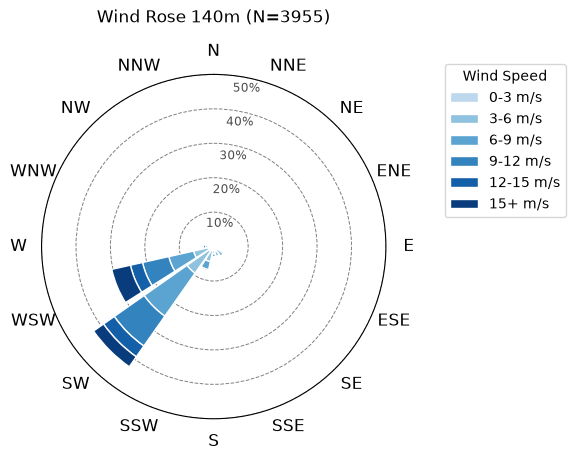

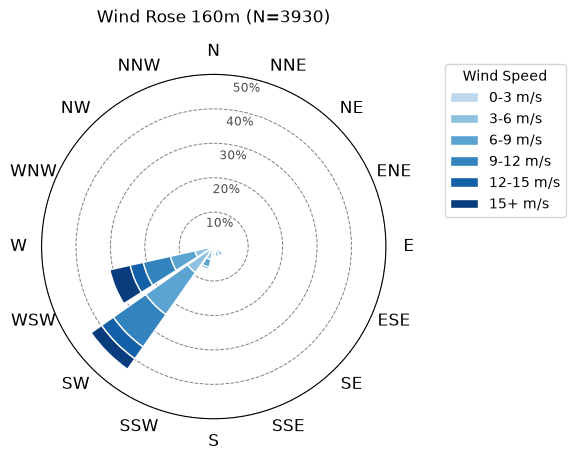

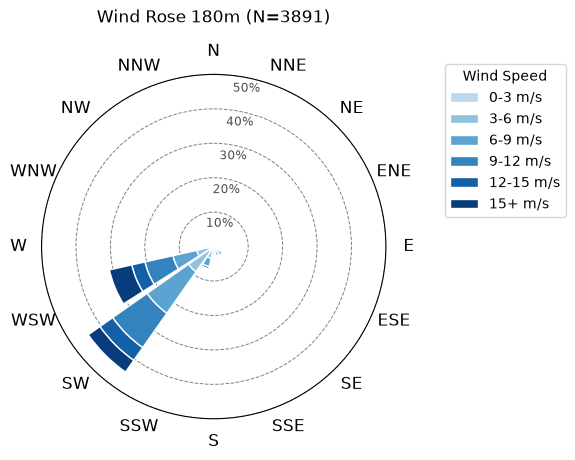

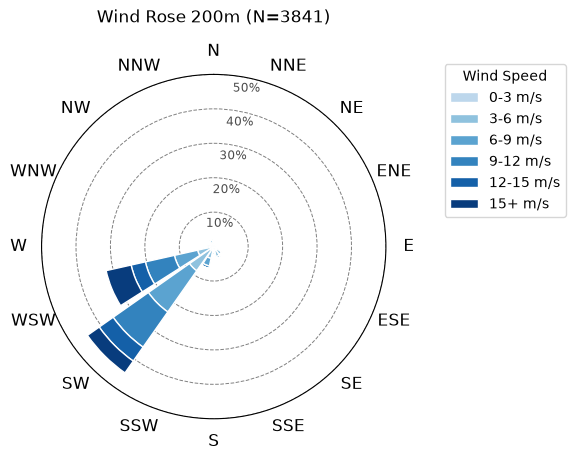

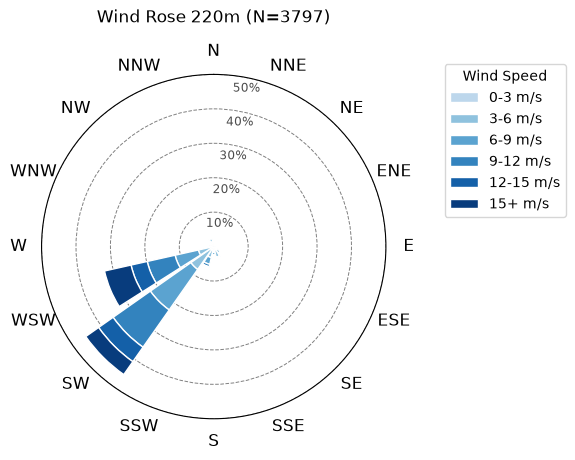

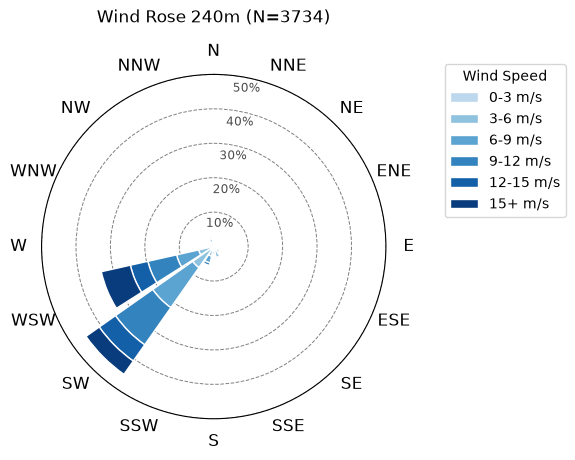

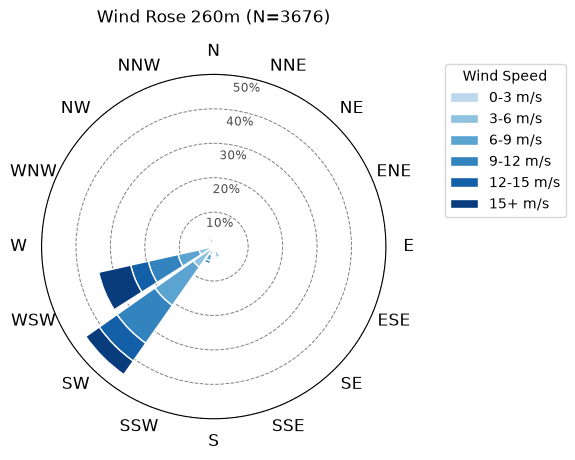

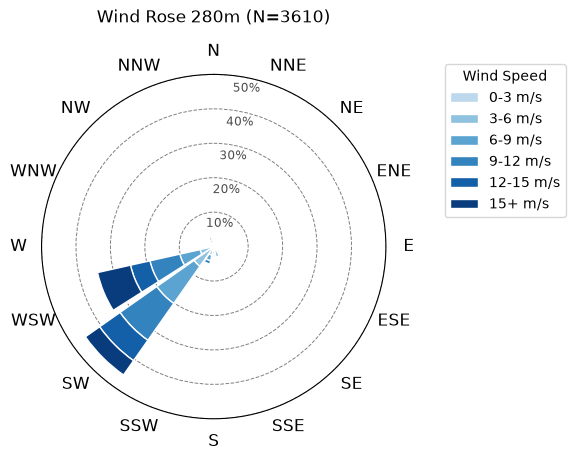

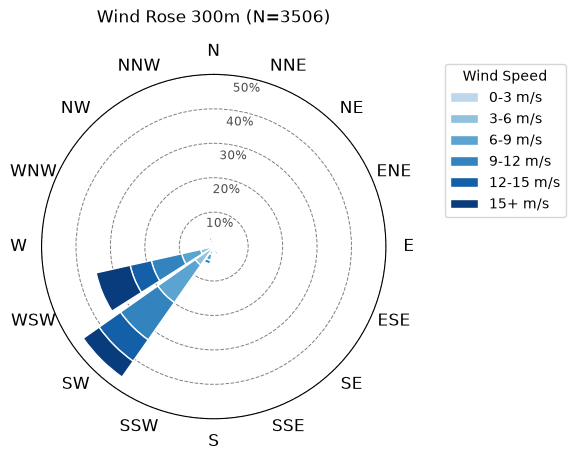

In [14]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 期間を指定する場合は日時を設定（全期間を使う場合は None に設定）
START_TIME = None  # 例: "2025-02-12 20:00:00"
END_TIME = None    # 例: "2025-02-13 03:00:00"

if START_TIME is not None and END_TIME is not None:
    ts = pd.to_datetime(df["Timestamp (end of interval)"])
    df_target = df[(ts >= pd.to_datetime(START_TIME)) & (ts <= pd.to_datetime(END_TIME))].copy()
else:
    df_target = df.copy()

# 風配図（Wind Rose）描画設定（16方位・風速階級別積み上げ）
SPEED_BINS = [0, 3, 6, 9, 12, 15, np.inf]
SPEED_LABELS = ["0-3", "3-6", "6-9", "9-12", "12-15", "15+"]
DIR_LABELS = [
    "N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"
]

heights = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]
n_sectors = 16
sector_width = 360.0 / n_sectors  # 22.5度

# ============================================================
# 全高度の中から風向出現頻度の最大値(%)を取得して上限を統一
# ============================================================
max_freq = 0.0
for n in heights:
    speed_col = f"{n}m Wind Speed (m/s)"
    dir_col = f"{n}m Wind Direction (ｰ)"
    sub = df_target[[speed_col, dir_col]].dropna()
    if len(sub) > 0:
        direction = sub[dir_col].to_numpy()
        sector_idx = np.floor(((direction + sector_width / 2) % 360) / sector_width).astype(int)
        counts = np.bincount(sector_idx, minlength=n_sectors)
        max_freq = max(max_freq, (counts.max() / len(sub)) * 100.0)

# 目盛り間隔（5%刻み、最大値が10%以下の場合は2%刻み）で上限値を算出
step = 5.0 if max_freq > 10.0 else 2.0
max_ylim = np.ceil((max_freq * 1.05) / step) * step
yticks = np.arange(step, max_ylim + 0.1, step)


def plot_windrose(ax, speed, direction, max_ylim, yticks, title=""):
    # 北(0度)を中心に22.5度ずつ16方位へ分類
    sector_idx = np.floor(((direction + sector_width / 2) % 360) / sector_width).astype(int)
    angles = np.deg2rad(np.arange(0, 360, sector_width))
    width = np.deg2rad(sector_width * 0.88)

    total_count = len(speed)
    bottom = np.zeros(n_sectors)
    # 青系の色の濃淡（淡い青〜濃い青）
    colors = cm.Blues(np.linspace(0.28, 0.95, len(SPEED_LABELS)))

    for i, label in enumerate(SPEED_LABELS):
        in_bin = (speed >= SPEED_BINS[i]) & (speed < SPEED_BINS[i + 1])
        counts = np.bincount(sector_idx[in_bin], minlength=n_sectors)
        freq_pct = (counts / total_count) * 100.0 if total_count > 0 else np.zeros(n_sectors)

        ax.bar(
            angles,
            freq_pct,
            width=width,
            bottom=bottom,
            color=colors[i],
            edgecolor="white",
            linewidth=1,
            label=f"{label} m/s",
            zorder=3,  # ← 棒グラフの前後順（グリッド線より奥なら2、手前なら3）
        )
        bottom += freq_pct
    # %の同心円グリッド線の色・スタイル
    ax.yaxis.grid(True, color="black", linestyle="--", linewidth=0.7,alpha=0.5)
    ax.xaxis.grid(False)#color="black", linestyle="--", linewidth=0.7,alpha=0.5)

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_xticks(angles)
    ax.set_xticklabels(DIR_LABELS, fontsize=12)
    ax.tick_params(axis="x", pad=6)

    # 半径方向の上限を全高度で統一し、%ラベルが一番外の円と重ならないよう内側に配置
    ax.set_ylim(0, max_ylim)
    ax.set_yticks(yticks)
    ax.set_yticklabels([])

    label_angle = np.deg2rad(11.25)  # N と NNE の中間角度
    for y in yticks:
        ax.text(
            label_angle,
            y - max_ylim * 0.03,
            f"{y:.0f}%",
            ha="center",
            va="top",
            fontsize=8.5,
            color="black",
            alpha=0.7,
            zorder=5,  # ← %の文字は常に一番手前に表示
            #bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7),
        )

    ax.set_title(title, pad=15, fontsize=12)


# 高度リスト n = [40, 60, ..., 300] を繰り返して出力
for n in heights:
    speed_col = f"{n}m Wind Speed (m/s)"
    dir_col = f"{n}m Wind Direction (ｰ)"

    sub = df_target[[speed_col, dir_col]].dropna()

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": "polar"})
    plot_windrose(
        ax,
        sub[speed_col].to_numpy(),
        sub[dir_col].to_numpy(),
        max_ylim = np.ceil((max_freq * 1.05) / 5.0) * 5.0,
        yticks = np.arange(10.0, max_ylim + 0.1, 10.0),
        title=f"Wind Rose {n}m (N={len(sub)})",
    )
    ax.legend(title="Wind Speed", bbox_to_anchor=(1.15, 1.05), loc="upper left")
    plt.tight_layout()
    plt.show()
